In [1]:
!nvidia-smi

Sun Nov 22 07:16:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!ls /content

sample_data  SDCdataset.v2i.multiclass.zip


In [4]:
!unzip -q "/content/SDCdataset.v2i.multiclass.zip" -d /content/roboflow_download
!find /content/roboflow_download -maxdepth 2 | head -30

/content/roboflow_download
/content/roboflow_download/README.dataset.txt
/content/roboflow_download/valid
/content/roboflow_download/valid/23_02_06_288_Color_png.rf.2630213964d0e901e8823e42a5853ed1.jpg
/content/roboflow_download/valid/23_02_06_75_Color_png.rf.3912d10361adfba87b20ff00820e1b73.jpg
/content/roboflow_download/valid/23_02_06_22_Color_png.rf.a230e88a55d8dea5681ccac318fc67b5.jpg
/content/roboflow_download/valid/23_02_06_32_Color_png.rf.ceda6c1b4407a9f82b71c832a525205e.jpg
/content/roboflow_download/valid/2022_12_16_147_Color_png.rf.1451da27a46d9417b9729020d9022bb8.jpg
/content/roboflow_download/valid/23_02_06_149_Color_png.rf.c1e9519d3b06eafcc30f0dbdce282c02.jpg
/content/roboflow_download/valid/23_02_06_166_Color_png.rf.19269afefd5cfeb16a6ebac05ad0c7d8.jpg
/content/roboflow_download/valid/23_02_06_296_Color_png.rf.e9f44bbb7cba2fee4ee141a5923d497a.jpg
/content/roboflow_download/valid/23_02_06_330_Color_png.rf.4fdca096781e6c5cddd73a6625b46518.jpg
/content/roboflow_download/vali

In [5]:
import json, os

for split in ["train", "valid", "test"]:
    p = f"/content/roboflow_download/{split}"
    if not os.path.isdir(p):
        print(split, "-> folder missing")
        continue
    n_img = len([f for f in os.listdir(p) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    ann = os.path.join(p, "_annotations.coco.json")
    if os.path.exists(ann):
        d = json.load(open(ann))
        print(split, "| images:", n_img, "| annotations:", len(d["annotations"]), "| classes:", [c["name"] for c in d["categories"]])
    else:
        print(split, "| images:", n_img, "| NO _annotations.coco.json")

train | images: 259 | NO _annotations.coco.json
valid | images: 74 | NO _annotations.coco.json
test | images: 37 | NO _annotations.coco.json


In [6]:
import os

root = "/content/roboflow_download"
for split in ["train", "valid", "test"]:
    p = os.path.join(root, split)
    others = [f for f in os.listdir(p) if not f.lower().endswith((".jpg", ".jpeg", ".png"))]
    print(split, "-> non-image files:", others)

print("\n--- files directly in the main folder ---")
print(os.listdir(root))

print("\n--- README.dataset.txt ---")
print(open(os.path.join(root, "README.dataset.txt")).read()[:1500])

for f in os.listdir(os.path.join(root, "train")):
    if f.lower().endswith((".csv", ".json", ".txt")):
        print(f"\n--- first lines of train/{f} ---")
        print(open(os.path.join(root, "train", f)).read()[:600])

train -> non-image files: ['_classes.csv']
valid -> non-image files: ['_classes.csv']
test -> non-image files: ['_classes.csv']

--- files directly in the main folder ---
['README.dataset.txt', 'valid', 'test', 'train', 'README.roboflow.txt']

--- README.dataset.txt ---
# screwdetectclassification-xrrbi-gdsj > 2025-03-13 12:45am
https://universe.roboflow.com/roboflow100vl-full/screwdetectclassification-xrrbi-gdsj

Provided by a Roboflow user
License: MIT

# Overview
- [Introduction](#introduction)
- [Object Classes](#object-classes)
  - [Hex Washer Screw](#hex-washer-screw)
  - [Hexagonal Bolt](#hexagonal-bolt)
  - [Philips Screw](#philips-screw)
  - [Pozidriv Screw](#pozidriv-screw)
  - [Torx Screw](#torx-screw)

# Introduction
This dataset aims to facilitate the classification and detection of various types of screws and bolts. It contains images of different fasteners used in mechanical installations. The classes include Hex Washer Screw, Hexagonal Bolt, Philips Screw, Pozidriv Scre

In [7]:
import pandas as pd, shutil
from pathlib import Path

SRC = Path("/content/roboflow_download")
DST = Path("/content/dataset")
if DST.exists():
    shutil.rmtree(DST)

for split in ["train", "valid", "test"]:
    df = pd.read_csv(SRC / split / "_classes.csv")
    df.columns = [c.strip() for c in df.columns]
    class_cols = [c for c in df.columns if c != "filename"]
    df["n_labels"] = df[class_cols].sum(axis=1)

    print(f"\n=== {split}: {len(df)} images ===")
    print("Labels per image:", df["n_labels"].value_counts().sort_index().to_dict(), "(0 = no part, 1 = one type, 2+ = mixed)")

    single = df[df["n_labels"] == 1]
    for _, row in single.iterrows():
        cls = [c for c in class_cols if row[c] == 1][0].replace(" ", "_")
        out = DST / split / cls
        out.mkdir(parents=True, exist_ok=True)
        shutil.copy(SRC / split / row["filename"], out / row["filename"])

    print("Kept (single-label):", {c.name: len(list(c.glob('*.jpg'))) for c in sorted((DST / split).iterdir())})


=== train: 259 images ===
Labels per image: {1: 168, 2: 82, 3: 9} (0 = no part, 1 = one type, 2+ = mixed)
Kept (single-label): {'Hex_Washer_Screw': 10, 'Hexagonal_Bolt': 18, 'Philips_Screw': 46, 'Pozidriv_Screw': 5, 'Torx_Screw': 89}

=== valid: 74 images ===
Labels per image: {1: 47, 2: 26, 3: 1} (0 = no part, 1 = one type, 2+ = mixed)
Kept (single-label): {'Hex_Washer_Screw': 4, 'Hexagonal_Bolt': 4, 'Philips_Screw': 12, 'Pozidriv_Screw': 3, 'Torx_Screw': 24}

=== test: 37 images ===
Labels per image: {1: 23, 2: 12, 3: 2} (0 = no part, 1 = one type, 2+ = mixed)
Kept (single-label): {'Hex_Washer_Screw': 1, 'Hexagonal_Bolt': 3, 'Philips_Screw': 7, 'Pozidriv_Screw': 1, 'Torx_Screw': 11}


In [8]:
import pandas as pd, shutil
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold

SRC = Path("/content/roboflow_download")
DST = Path("/content/dataset")
if DST.exists():
    shutil.rmtree(DST)

# 1) collect every image that has exactly one screw type
rows = []
for split in ["train", "valid", "test"]:
    df = pd.read_csv(SRC / split / "_classes.csv")
    df.columns = [c.strip() for c in df.columns]
    class_cols = [c for c in df.columns if c != "filename"]
    df = df[df[class_cols].sum(axis=1) == 1].copy()
    df["label"] = df[class_cols].idxmax(axis=1).str.replace(" ", "_")
    df["src_path"] = [str(SRC / split / f) for f in df["filename"]]
    rows.append(df[["filename", "label", "src_path"]])
all_df = pd.concat(rows, ignore_index=True)

# 2) images made from the same original photo share one "group"
all_df["group"] = all_df["filename"].str.split(".rf.").str[0]
print("Total single-label images:", len(all_df))
print("Images that are extra copies of the same photo:", int(all_df["group"].duplicated().sum()))

# 3) split about 72% train / 14% val / 14% test, keeping classes balanced and groups together
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
rest_idx, test_idx = next(sgkf.split(all_df, all_df["label"], all_df["group"]))
rest = all_df.iloc[rest_idx]
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_i, va_i = next(sgkf2.split(rest, rest["label"], rest["group"]))

all_df["split"] = "train"
all_df.loc[all_df.index[test_idx], "split"] = "test"
all_df.loc[rest.index[va_i], "split"] = "val"

# 4) copy into dataset/<split>/<class>/
for _, r in all_df.iterrows():
    out = DST / r["split"] / r["label"]
    out.mkdir(parents=True, exist_ok=True)
    shutil.copy(r["src_path"], out / r["filename"])

print()
print(pd.crosstab(all_df["label"], all_df["split"])[["train", "val", "test"]])

Total single-label images: 238
Images that are extra copies of the same photo: 0

split             train  val  test
label                             
Hex_Washer_Screw     11    1     3
Hexagonal_Bolt       18    4     3
Philips_Screw        48    8     9
Pozidriv_Screw        6    2     1
Torx_Screw           87   19    18


In [9]:
import os, json, hashlib, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, cv2
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
SEED = 42
random.seed(SEED); np.random.seed(SEED)

DATA_DIR = Path("/content/dataset")
OUT_DIR = Path("/content/processed"); OUT_DIR.mkdir(exist_ok=True)
IMG_SIZE = 224
MIN_SIDE = 64
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

# ---- load all images into a table ----
rows = []
for p in sorted(DATA_DIR.rglob("*.jpg")):
    split, label = p.relative_to(DATA_DIR).parts[0], p.relative_to(DATA_DIR).parts[1]
    rows.append({"path": str(p), "label": label, "split": split})
df = pd.DataFrame(rows)
print("Images:", len(df), "| Classes:", df["label"].nunique())

# ---- measure every image ----
def image_stats(path):
    img = cv2.imread(path)
    if img is None:
        return {"corrupt": True}
    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    b, g, r = img.reshape(-1, 3).mean(axis=0)
    return {"corrupt": False, "width": w, "height": h, "aspect": w / h,
            "brightness": gray.mean(), "contrast": gray.std(),
            "sharpness": cv2.Laplacian(gray, cv2.CV_64F).var(),
            "mean_r": r, "mean_g": g, "mean_b": b,
            "md5": hashlib.md5(Path(path).read_bytes()).hexdigest()}

df = pd.concat([df, pd.DataFrame([image_stats(p) for p in df["path"]])], axis=1)

# ---- quality report ----
print("Corrupt images:", int(df["corrupt"].sum()))
print("Exact duplicate images:", int(df[~df["corrupt"]].duplicated("md5").sum()))
print("Low-resolution images:", int((df[["width", "height"]].min(axis=1) < MIN_SIDE).sum()))
cross = df.groupby("md5")["split"].nunique().gt(1).sum()
print("Same image in more than one split (leakage):", int(cross))

# ---- clean ----
before = len(df)
df = df[~df["corrupt"]].drop_duplicates("md5").reset_index(drop=True)
print(f"Removed {before - len(df)} images -> {len(df)} clean images remain")
display(pd.crosstab(df["label"], df["split"])[["train", "val", "test"]])

Images: 238 | Classes: 5
Corrupt images: 0
Exact duplicate images: 0
Low-resolution images: 0
Same image in more than one split (leakage): 0
Removed 0 images -> 238 clean images remain


split,train,val,test
label,,,
Hex_Washer_Screw,11,1,3
Hexagonal_Bolt,18,4,3
Philips_Screw,48,8,9
Pozidriv_Screw,6,2,1
Torx_Screw,87,19,18


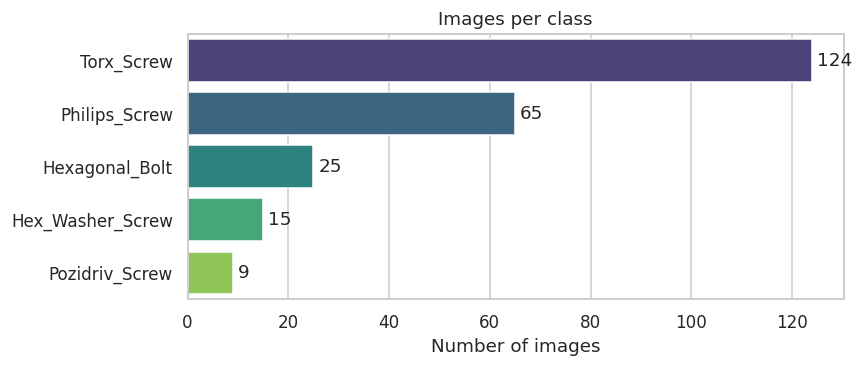

Imbalance ratio (largest / smallest class): 13.8


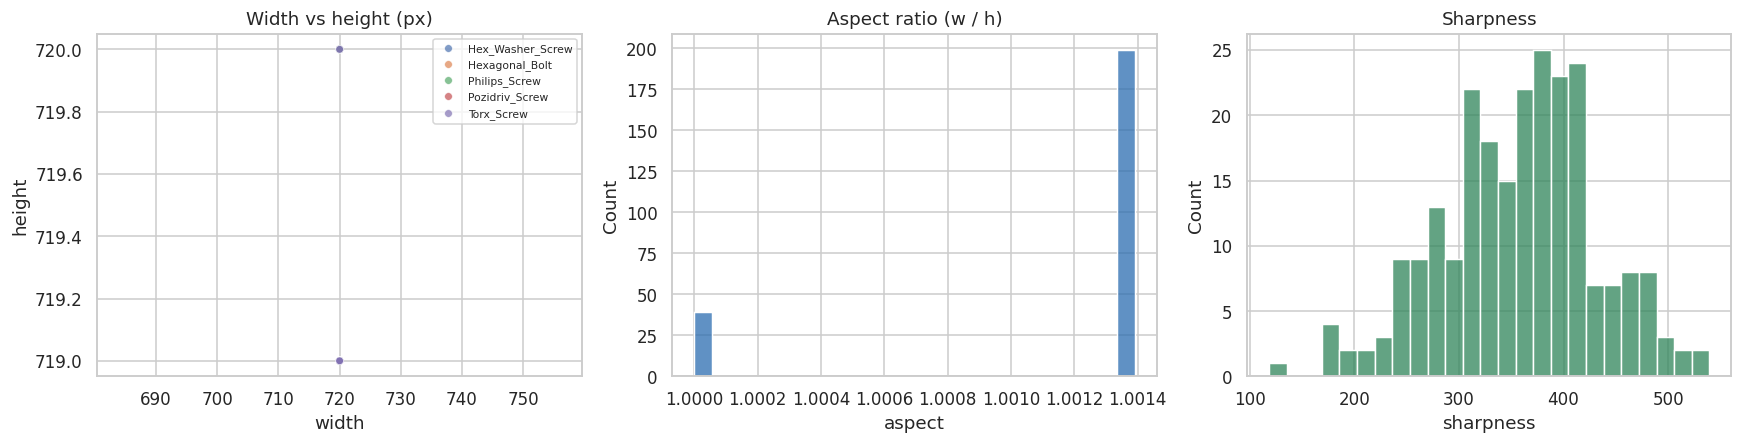

,width,height,aspect
count,238.0,238.00,238.0
mean,720.0,719.16,1.0
std,0.0,0.37,0.0
min,720.0,719.00,1.0
25%,720.0,719.00,1.0
50%,720.0,719.00,1.0
75%,720.0,719.00,1.0
max,720.0,720.00,1.0


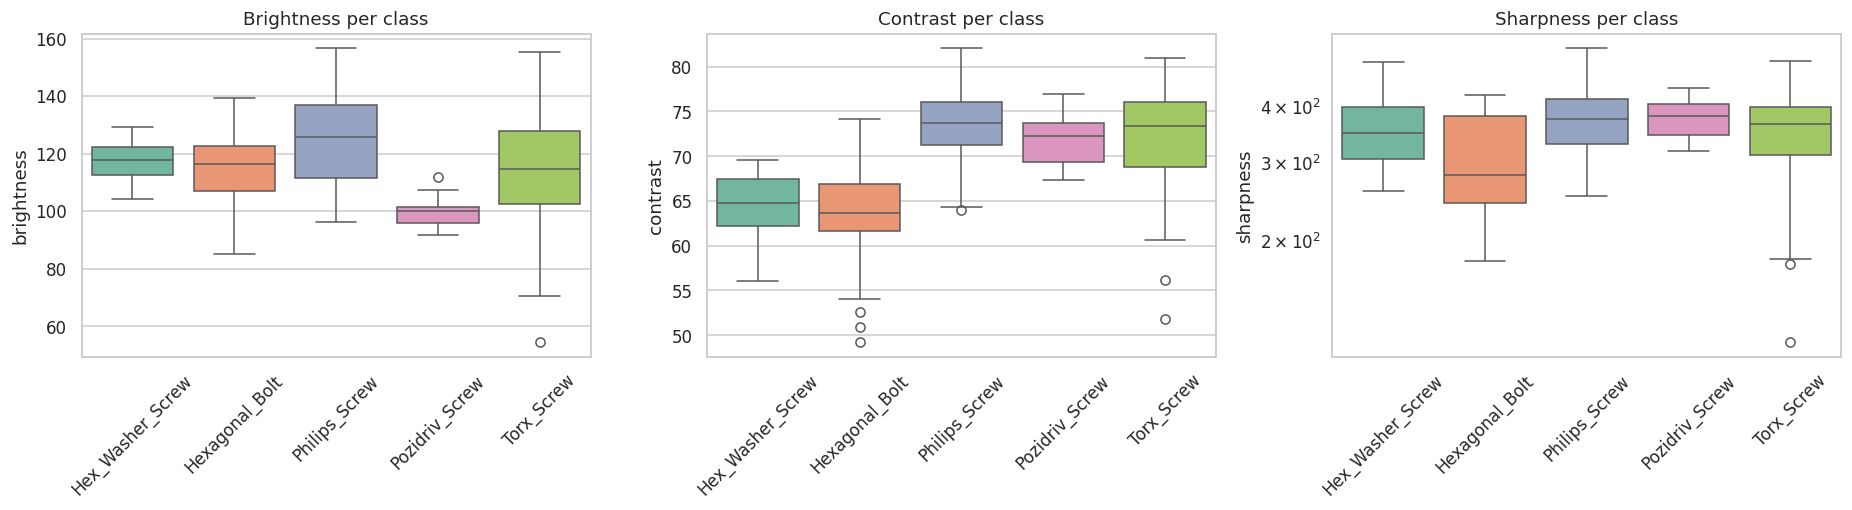

In [10]:
counts = df["label"].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=counts.values, y=counts.index, ax=ax, palette="viridis")
for i, v in enumerate(counts.values):
    ax.text(v + 1, i, str(v), va="center")
ax.set_title("Images per class"); ax.set_xlabel("Number of images"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.scatterplot(data=df, x="width", y="height", hue="label", s=25, alpha=0.7, ax=axes[0])
axes[0].set_title("Width vs height (px)"); axes[0].legend(fontsize=7)
sns.histplot(df["aspect"], bins=25, ax=axes[1], color="#2b6cb0"); axes[1].set_title("Aspect ratio (w / h)")
sns.histplot(df["sharpness"], bins=25, ax=axes[2], color="#2f855a"); axes[2].set_title("Sharpness")
plt.tight_layout(); plt.show()
display(df[["width", "height", "aspect"]].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, col, title in zip(axes, ["brightness", "contrast", "sharpness"],
                          ["Brightness per class", "Contrast per class", "Sharpness per class"]):
    sns.boxplot(data=df, x="label", y=col, ax=ax, palette="Set2")
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
    if col == "sharpness": ax.set_yscale("log")
plt.tight_layout(); plt.show()

,mean_r,mean_g,mean_b
label,,,
Hex_Washer_Screw,109.0,120.0,124.2
Hexagonal_Bolt,107.0,117.9,120.4
Philips_Screw,117.3,128.3,129.9
Pozidriv_Screw,91.0,103.5,105.3
Torx_Screw,105.5,118.6,121.3


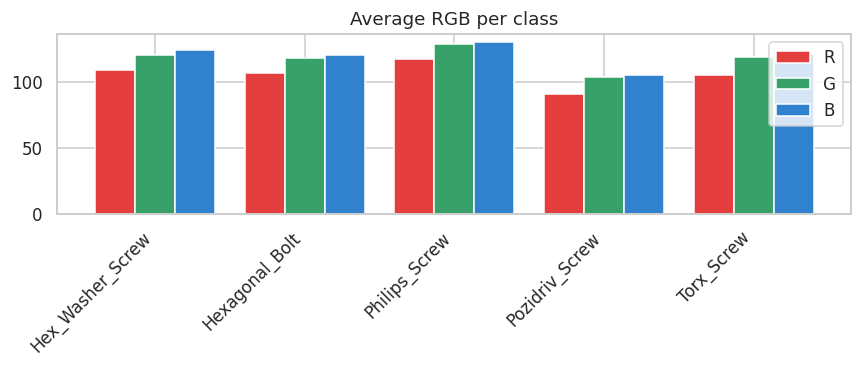

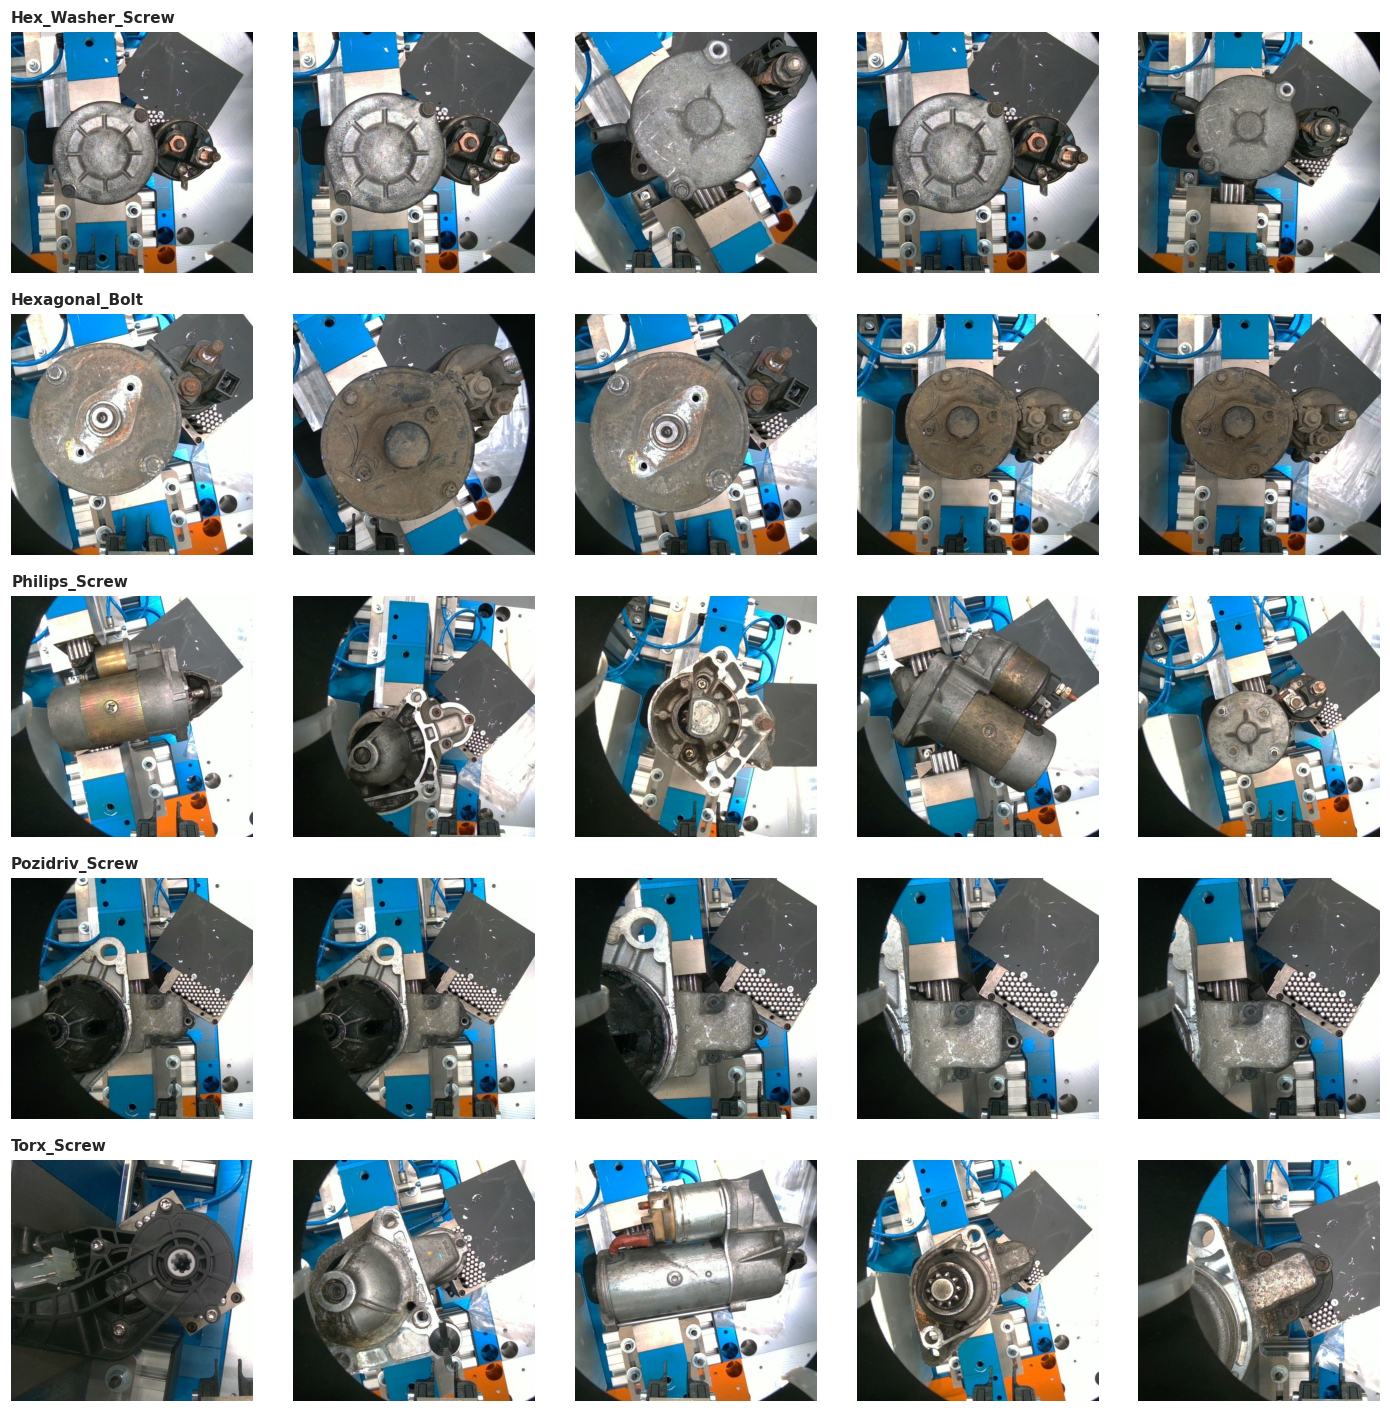

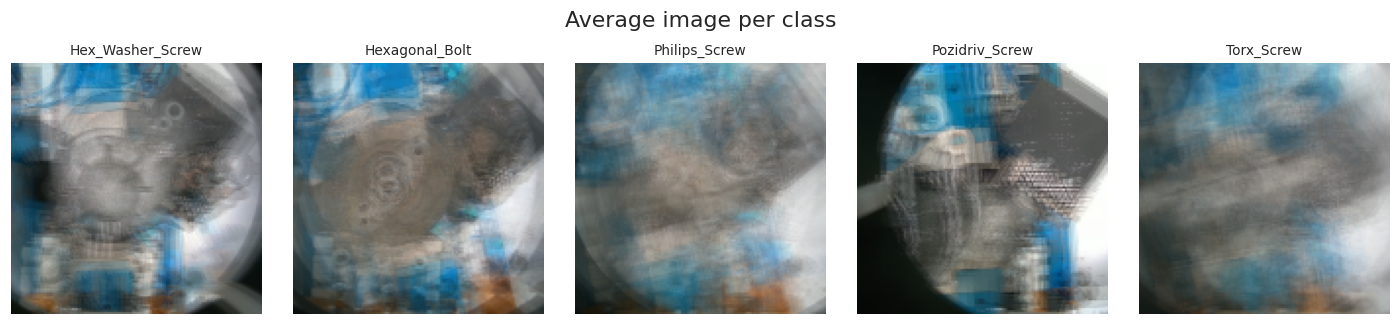

In [11]:
color = df.groupby("label")[["mean_r", "mean_g", "mean_b"]].mean().round(1)
display(color)
color.plot(kind="bar", figsize=(8, 3.5), color=["#e53e3e", "#38a169", "#3182ce"], width=0.8)
plt.title("Average RGB per class"); plt.xlabel(""); plt.xticks(rotation=45, ha="right")
plt.legend(["R", "G", "B"]); plt.tight_layout(); plt.show()

def read_rgb(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

classes = sorted(df["label"].unique())
n_show = 5
fig, axes = plt.subplots(len(classes), n_show, figsize=(2.6 * n_show, 2.6 * len(classes)))
for i, c in enumerate(classes):
    sample = df[df["label"] == c].sample(min(n_show, (df["label"] == c).sum()), random_state=SEED)
    for j in range(n_show):
        axes[i, j].axis("off")
        if j < len(sample):
            axes[i, j].imshow(read_rgb(sample.iloc[j]["path"]))
        if j == 0:
            axes[i, j].set_title(c, loc="left", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(classes), figsize=(2.6 * len(classes), 3))
for ax, c in zip(axes, classes):
    paths = df[df["label"] == c]["path"].head(60)
    avg = np.mean([cv2.resize(read_rgb(p), (128, 128)) for p in paths], axis=0).astype(np.uint8)
    ax.imshow(avg); ax.set_title(c, fontsize=9); ax.axis("off")
plt.suptitle("Average image per class"); plt.tight_layout(); plt.show()

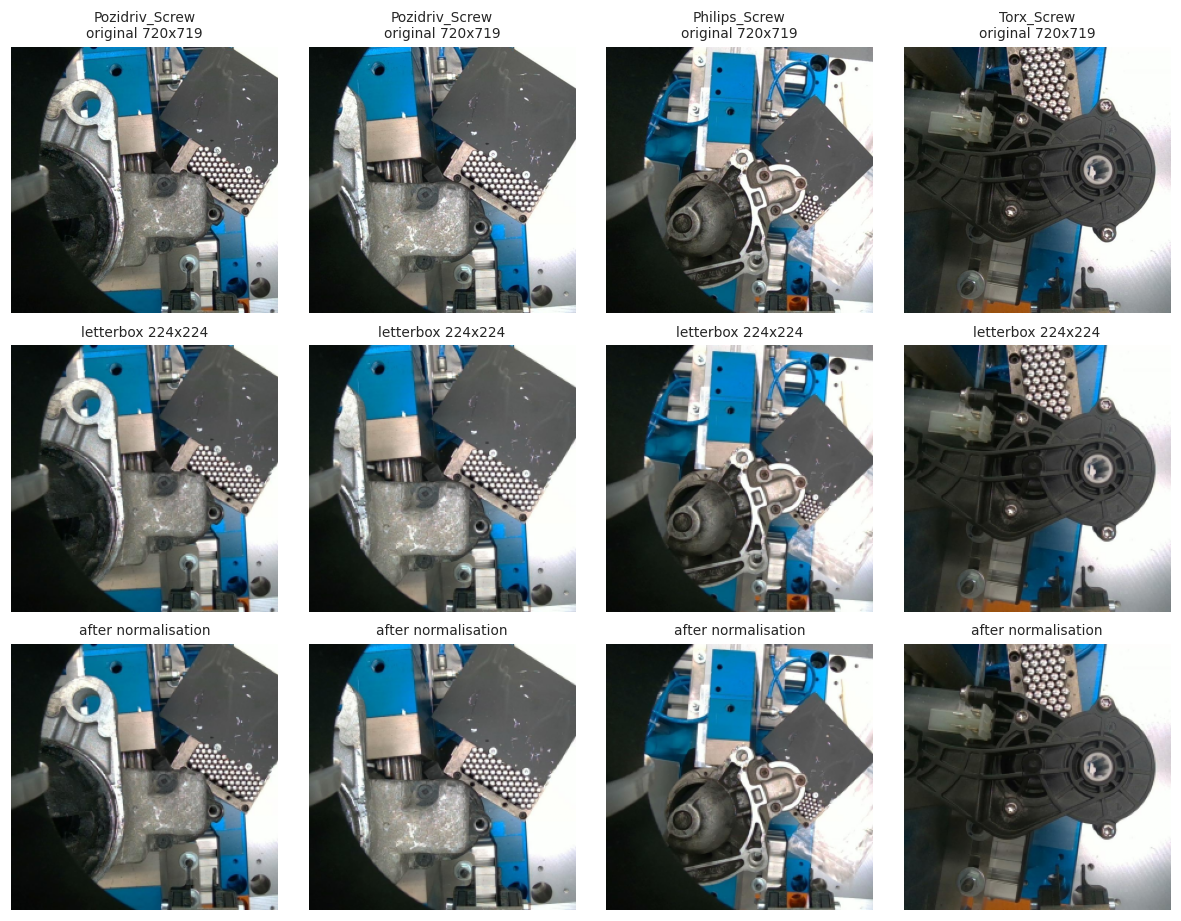

Tensor shape: (224, 224, 3) | dtype: float32


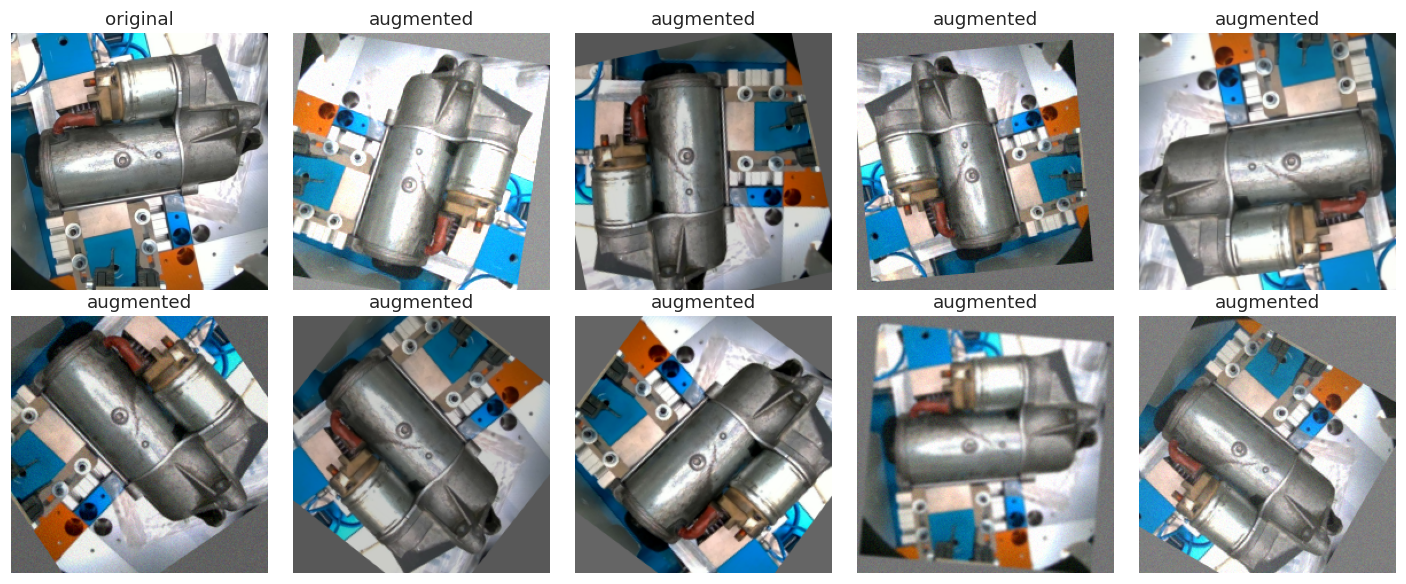

In [12]:
def letterbox(img, size=IMG_SIZE, pad_value=114):
    h, w = img.shape[:2]
    scale = size / max(h, w)
    nh, nw = max(1, int(round(h * scale))), max(1, int(round(w * scale)))
    resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR)
    canvas = np.full((size, size, 3), pad_value, dtype=np.uint8)
    top, left = (size - nh) // 2, (size - nw) // 2
    canvas[top:top + nh, left:left + nw] = resized
    return canvas

def preprocess(path):
    img = letterbox(read_rgb(path))
    return (img.astype(np.float32) / 255.0 - MEAN) / STD

def denormalize(arr):
    return np.clip(arr * STD + MEAN, 0, 1)

def augment(img, rng):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-180, 180), rng.uniform(0.85, 1.10))
    M[:, 2] += rng.uniform(-0.06, 0.06, size=2) * [w, h]
    out = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=(114, 114, 114))
    if rng.random() < 0.5:
        out = cv2.flip(out, 1)
    out = np.clip(out.astype(np.float32) * rng.uniform(0.75, 1.25) + rng.uniform(-25, 25), 0, 255).astype(np.uint8)
    if rng.random() < 0.3:
        k = int(rng.choice([3, 5])); out = cv2.GaussianBlur(out, (k, k), 0)
    if rng.random() < 0.3:
        out = np.clip(out + rng.normal(0, 6, out.shape), 0, 255).astype(np.uint8)
    return out

# original -> letterbox -> normalised
ex = df.sample(4, random_state=SEED)
fig, axes = plt.subplots(3, 4, figsize=(11, 8.5))
for j, (_, r) in enumerate(ex.iterrows()):
    raw = read_rgb(r["path"])
    axes[0, j].imshow(raw); axes[0, j].set_title(f"{r['label']}\noriginal {raw.shape[1]}x{raw.shape[0]}", fontsize=9)
    axes[1, j].imshow(letterbox(raw)); axes[1, j].set_title("letterbox 224x224", fontsize=9)
    axes[2, j].imshow(denormalize(preprocess(r["path"]))); axes[2, j].set_title("after normalisation", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()
t = preprocess(ex.iloc[0]["path"])
print("Tensor shape:", t.shape, "| dtype:", t.dtype)

# augmentation examples
rng = np.random.default_rng(SEED)
base = letterbox(read_rgb(df.sample(1, random_state=7).iloc[0]["path"]))
fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
axes[0, 0].imshow(base); axes[0, 0].set_title("original")
for ax in axes.ravel()[1:]:
    ax.imshow(augment(base, rng)); ax.set_title("augmented")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

Class weights: {'Hex_Washer_Screw': 3.091, 'Hexagonal_Bolt': 1.889, 'Philips_Screw': 0.708, 'Pozidriv_Screw': 5.667, 'Torx_Screw': 0.391}


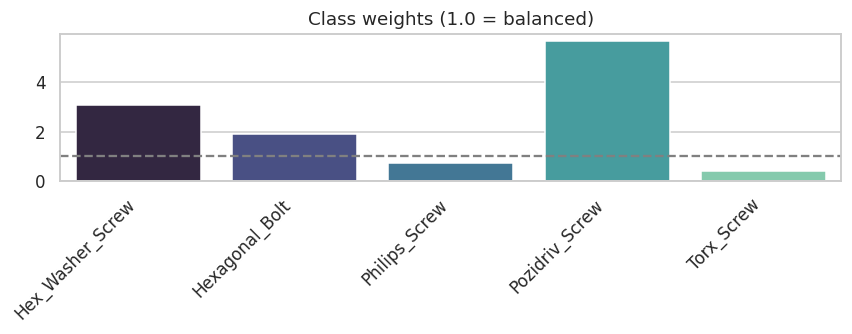

Saved: ['class_to_idx.json', 'class_weights.json', 'metadata.csv']


In [13]:
classes = sorted(df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["label_idx"] = df["label"].map(class_to_idx)

train_labels = df.loc[df["split"] == "train", "label_idx"].values
weights = compute_class_weight("balanced", classes=np.arange(len(classes)), y=train_labels)
class_weights = {classes[i]: round(float(w), 3) for i, w in enumerate(weights)}
print("Class weights:", class_weights)

fig, ax = plt.subplots(figsize=(8, 3.2))
sns.barplot(x=list(class_weights.keys()), y=list(class_weights.values()), ax=ax, palette="mako")
ax.axhline(1.0, color="gray", ls="--"); ax.set_title("Class weights (1.0 = balanced)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

cols = ["path", "label", "label_idx", "split", "width", "height", "brightness", "contrast", "sharpness"]
df[cols].to_csv(OUT_DIR / "metadata.csv", index=False)
json.dump(class_to_idx, open(OUT_DIR / "class_to_idx.json", "w"), indent=2)
json.dump(class_weights, open(OUT_DIR / "class_weights.json", "w"), indent=2)
print("Saved:", sorted(f.name for f in OUT_DIR.iterdir()))

Device: cuda | Tesla T4
Train: 170 | Val: 34 | Test: 34
Batch tensor shape: (16, 3, 224, 224)


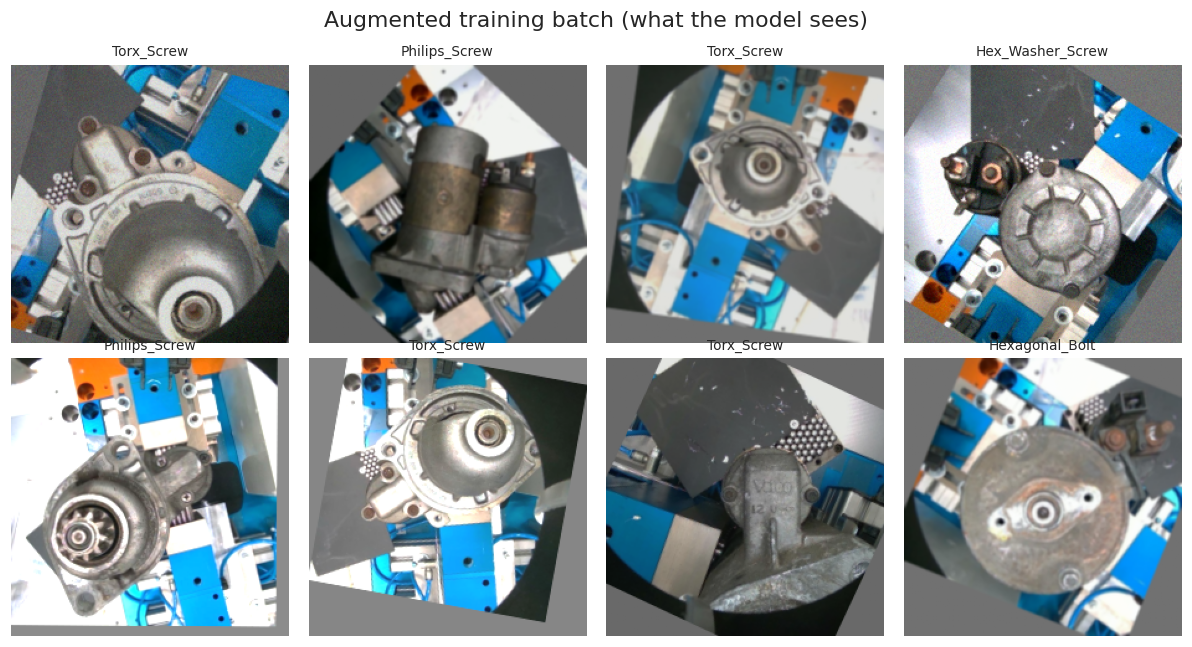

In [14]:
import time
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix, f1_score

torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "NO GPU!")

BATCH_SIZE = 16
MODEL_DIR = Path("/content/models"); MODEL_DIR.mkdir(exist_ok=True)

meta = pd.read_csv(OUT_DIR / "metadata.csv")
idx_to_class = {v: k for k, v in class_to_idx.items()}
NUM_CLASSES = len(class_to_idx)
train_df = meta[meta["split"] == "train"].reset_index(drop=True)
val_df = meta[meta["split"] == "val"].reset_index(drop=True)
test_df = meta[meta["split"] == "test"].reset_index(drop=True)
print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))

def to_model_input(img_rgb):
    x = (img_rgb.astype(np.float32) / 255.0 - MEAN) / STD
    return np.ascontiguousarray(x.transpose(2, 0, 1))

def load_input(path, train=False):
    img = letterbox(read_rgb(path))
    if train:
        img = augment(img, np.random.default_rng())
    return to_model_input(img)

class ComponentDataset(Dataset):
    def __init__(self, df, train=False):
        self.paths, self.labels, self.train = df["path"].tolist(), df["label_idx"].tolist(), train
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return torch.from_numpy(load_input(self.paths[i], self.train)), self.labels[i]

drop_last = len(train_df) % BATCH_SIZE == 1
train_loader = DataLoader(ComponentDataset(train_df, True), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=drop_last)
val_loader = DataLoader(ComponentDataset(val_df, False), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(ComponentDataset(test_df, False), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

xb, yb = next(iter(train_loader))
print("Batch tensor shape:", tuple(xb.shape))
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for ax, x, y in zip(axes.ravel(), xb[:8], yb[:8]):
    ax.imshow(np.clip(x.numpy().transpose(1, 2, 0) * STD + MEAN, 0, 1))
    ax.set_title(idx_to_class[int(y)], fontsize=9); ax.axis("off")
plt.suptitle("Augmented training batch (what the model sees)"); plt.tight_layout(); plt.show()

In [15]:
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model = model.to(DEVICE)
print(f"EfficientNet-B0 loaded | parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M | classes: {NUM_CLASSES}")

weight_tensor = torch.tensor([class_weights[idx_to_class[i]] for i in range(NUM_CLASSES)], dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=weight_tensor)
use_amp = DEVICE.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

history = []
best = {"val_acc": -1.0, "val_loss": float("inf")}
backbone_trainable = False

def set_backbone_trainable(flag):
    global backbone_trainable
    backbone_trainable = flag
    for p in model.features.parameters():
        p.requires_grad = flag

def run_epoch(loader, train, optimizer=None):
    model.train(train)
    if train and not backbone_trainable:
        model.features.eval()
    loss_sum, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type="cuda", enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            loss_sum += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return loss_sum / n, correct / n

def fit(epochs, optimizer, stage, scheduler=None, patience=None):
    no_improve = 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(train_loader, True, optimizer)
        vl, va = run_epoch(val_loader, False)
        if scheduler is not None:
            scheduler.step()
        history.append(dict(stage=stage, epoch=len(history) + 1, train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va))
        improved = va > best["val_acc"] or (va == best["val_acc"] and vl < best["val_loss"])
        if improved:
            best.update(val_acc=float(va), val_loss=float(vl))
            torch.save({"model_state": model.state_dict(), "class_to_idx": class_to_idx,
                        "img_size": IMG_SIZE, "arch": "efficientnet_b0", "val_acc": float(va)}, MODEL_DIR / "best_model.pt")
            no_improve = 0
        else:
            no_improve += 1
        print(f"[{stage}] epoch {ep:2d}/{epochs} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time() - t0:.0f}s" + ("  <- best, saved" if improved else ""))
        if patience is not None and no_improve >= patience:
            print(f"Early stopping: no improvement for {patience} epochs.")
            break

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 79.0MB/s]


EfficientNet-B0 loaded | parameters: 4.01M | classes: 5


[head] epoch  1/5 | train loss 1.529 acc 0.294 | val loss 1.162 acc 0.559 | 11s  <- best, saved
[head] epoch  2/5 | train loss 1.129 acc 0.694 | val loss 1.098 acc 0.647 | 4s  <- best, saved
[head] epoch  3/5 | train loss 0.809 acc 0.694 | val loss 0.865 acc 0.706 | 2s  <- best, saved
[head] epoch  4/5 | train loss 0.658 acc 0.747 | val loss 0.667 acc 0.882 | 3s  <- best, saved
[head] epoch  5/5 | train loss 0.568 acc 0.812 | val loss 0.631 acc 0.941 | 2s  <- best, saved
[finetune] epoch  1/15 | train loss 1.234 acc 0.582 | val loss 0.495 acc 0.882 | 5s
[finetune] epoch  2/15 | train loss 0.849 acc 0.771 | val loss 0.451 acc 0.853 | 2s
[finetune] epoch  3/15 | train loss 0.600 acc 0.741 | val loss 0.385 acc 0.882 | 3s
[finetune] epoch  4/15 | train loss 0.589 acc 0.782 | val loss 0.311 acc 0.912 | 2s
[finetune] epoch  5/15 | train loss 0.410 acc 0.859 | val loss 0.246 acc 0.941 | 2s  <- best, saved
[finetune] epoch  6/15 | train loss 0.372 acc 0.894 | val loss 0.200 acc 1.000 | 2s  <- 

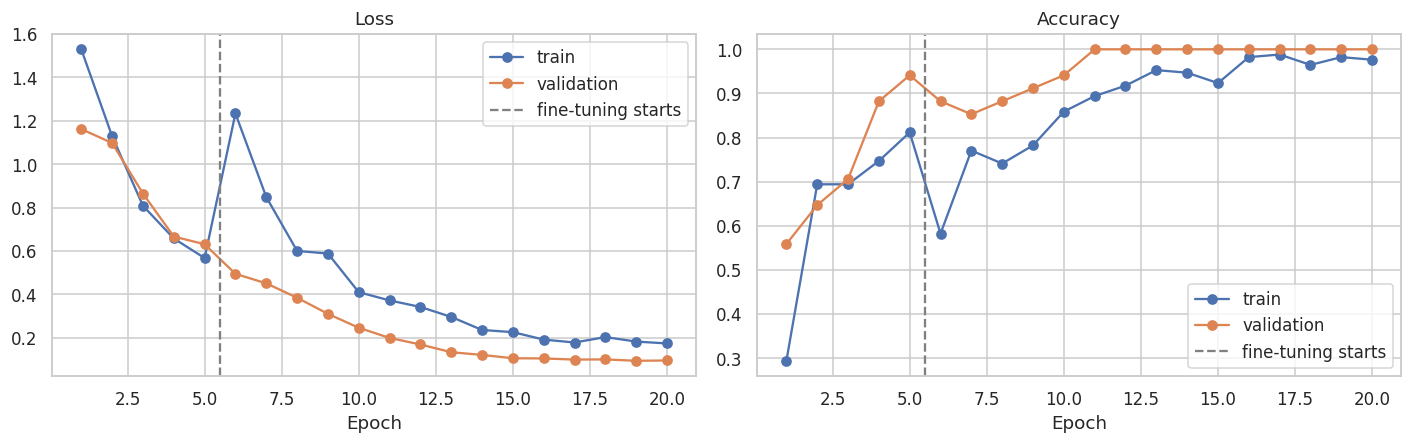

In [16]:
# Stage 1: only the new final layer learns (the pre-trained part is frozen)
set_backbone_trainable(False)
opt_head = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
fit(5, opt_head, stage="head")

# Stage 2: the whole network is fine-tuned with a smaller learning rate
set_backbone_trainable(True)
opt_ft = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt_ft, T_max=15)
fit(15, opt_ft, stage="finetune", scheduler=sched, patience=5)
print(f"\nBest validation accuracy: {best['val_acc']:.3f}")

# Training curves
hist = pd.DataFrame(history)
hist.to_csv(MODEL_DIR / "training_history.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (a, b), title in zip(axes, [("train_loss", "val_loss"), ("train_acc", "val_acc")], ["Loss", "Accuracy"]):
    ax.plot(hist["epoch"], hist[a], marker="o", label="train")
    ax.plot(hist["epoch"], hist[b], marker="o", label="validation")
    ft = hist.index[hist["stage"] == "finetune"]
    if len(ft):
        ax.axvline(hist.loc[ft[0], "epoch"] - 0.5, color="gray", ls="--", label="fine-tuning starts")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()

TEST RESULTS
  accuracy      : 1.000
  macro_f1      : 1.000
  top3_accuracy : 1.000

                  precision    recall  f1-score   support

Hex_Washer_Screw       1.00      1.00      1.00         3
  Hexagonal_Bolt       1.00      1.00      1.00         3
   Philips_Screw       1.00      1.00      1.00         9
  Pozidriv_Screw       1.00      1.00      1.00         1
      Torx_Screw       1.00      1.00      1.00        18

        accuracy                           1.00        34
       macro avg       1.00      1.00      1.00        34
    weighted avg       1.00      1.00      1.00        34



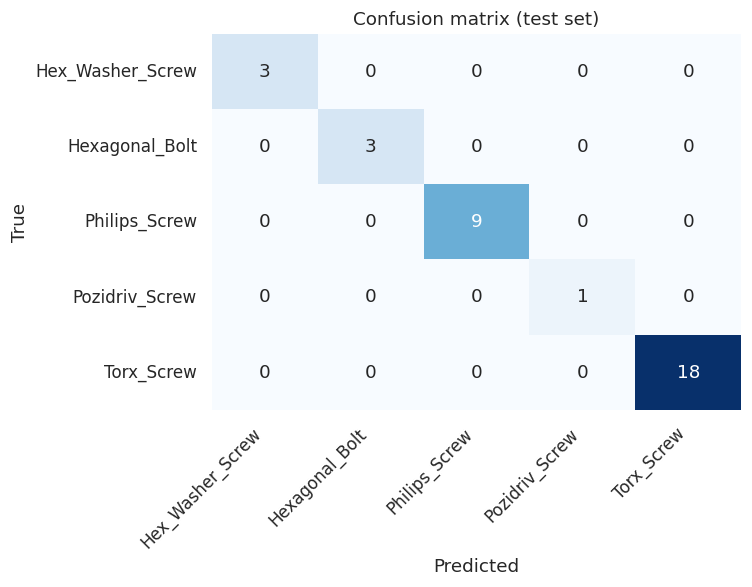

In [17]:
ckpt = torch.load(MODEL_DIR / "best_model.pt", map_location=DEVICE)
model.load_state_dict(ckpt["model_state"]); model.eval()

@torch.no_grad()
def predict_probs(loader):
    return np.concatenate([torch.softmax(model(x.to(DEVICE)), dim=1).cpu().numpy() for x, _ in loader])

probs = predict_probs(test_loader)
y_true = test_df["label_idx"].values
y_pred = probs.argmax(1)
names = [idx_to_class[i] for i in range(NUM_CLASSES)]

top3 = np.argsort(-probs, axis=1)[:, :3]
metrics = {"accuracy": float((y_pred == y_true).mean()),
           "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
           "top3_accuracy": float((top3 == y_true[:, None]).any(axis=1).mean())}
print("TEST RESULTS")
for k, v in metrics.items():
    print(f"  {k:14s}: {v:.3f}")
print()
print(classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=names, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax, cbar=False)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test set)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

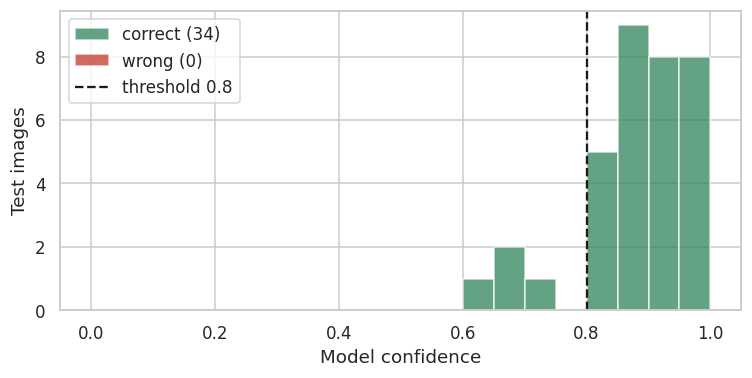

,threshold,auto-accepted (%),accuracy of accepted (%)
0,0.5,100.0,100.0
1,0.6,100.0,100.0
2,0.7,91.2,100.0
3,0.8,88.2,100.0
4,0.9,47.1,100.0


0 misclassified out of 34 test images


In [18]:
conf = probs.max(1)
correct = y_pred == y_true

fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(0, 1, 21)
ax.hist(conf[correct], bins=bins, alpha=0.75, label=f"correct ({correct.sum()})", color="#2f855a")
ax.hist(conf[~correct], bins=bins, alpha=0.75, label=f"wrong ({(~correct).sum()})", color="#c0392b")
ax.axvline(0.8, color="k", ls="--", label="threshold 0.8")
ax.set_xlabel("Model confidence"); ax.set_ylabel("Test images"); ax.legend()
plt.tight_layout(); plt.show()

rows = []
for t in (0.5, 0.6, 0.7, 0.8, 0.9):
    acc_mask = conf >= t
    rows.append({"threshold": t, "auto-accepted (%)": round(100 * acc_mask.mean(), 1),
                 "accuracy of accepted (%)": round(100 * (y_pred[acc_mask] == y_true[acc_mask]).mean(), 1) if acc_mask.any() else float("nan")})
display(pd.DataFrame(rows))

wrong = np.where(~correct)[0]
print(f"{len(wrong)} misclassified out of {len(test_df)} test images")
if len(wrong):
    fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong[:8]):
        ax.imshow(letterbox(read_rgb(test_df.loc[i, "path"])))
        ax.set_title(f"true: {names[y_true[i]]}\npred: {names[y_pred[i]]} ({conf[i]:.2f})", fontsize=9, color="#c0392b")
    plt.tight_layout(); plt.show()

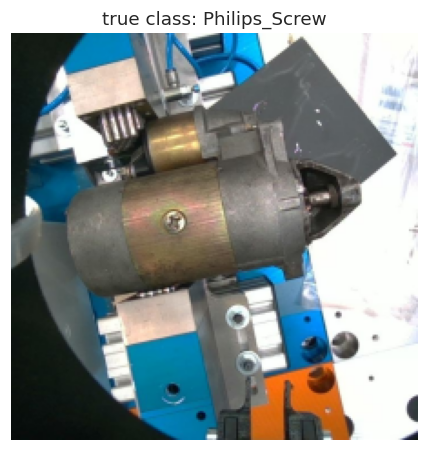

  Philips_Screw         93.6%
  Torx_Screw             3.3%
  Pozidriv_Screw         2.1%
-> ACCEPT automatically


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
json.dump({**metrics, "best_val_acc": best["val_acc"], "train_images": len(train_df),
           "val_images": len(val_df), "test_images": len(test_df)}, open(MODEL_DIR / "metrics.json", "w"), indent=2)
json.dump(class_to_idx, open(MODEL_DIR / "class_to_idx.json", "w"), indent=2)

def predict(path, k=3):
    model.eval()
    x = torch.from_numpy(to_model_input(letterbox(read_rgb(path)))).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        p = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    top = np.argsort(-p)[:k]
    return [(idx_to_class[int(i)], float(p[i])) for i in top]

row = test_df.sample(1, random_state=1).iloc[0]
plt.imshow(letterbox(read_rgb(row["path"]))); plt.axis("off"); plt.title(f"true class: {row['label']}"); plt.show()
result = predict(row["path"])
for name, c in result:
    print(f"  {name:20s} {c * 100:5.1f}%")
print("->", "ACCEPT automatically" if result[0][1] >= 0.8 else "LOW CONFIDENCE: ask user to confirm")

from google.colab import files
for f in ["best_model.pt", "class_to_idx.json", "metrics.json"]:
    files.download(str(MODEL_DIR / f))